# 03 — Classificação por Isolamento de Frequência e Voto no BETA

> **Adaptação de:** `SSVEP/classifier_per_freq.ipynb` ([bneurd/tutoriais](https://github.com/bneurd/tutoriais)).

## O que muda do `AVI` (7 classes) para o `BETA` (40 classes)?
1. **Limiar (`threshold`):** No dataset AVI, as 7 frequências (`6.0, 6.5, 7.0, 7.5, 8.2, 9.3, 10.0 Hz`) tinham distância mínima de `0.5 Hz`, permitindo `threshold = 0.25 Hz`. No **BETA**, existem **40 frequências** espaçadas a cada **`0.2 Hz`** (`8.0, 8.2, ..., 15.8 Hz`). Logo, usamos `threshold = 0.08 Hz` para isolar cada raia sem invadir a vizinha!
2. **Múltiplos Canais e Harmônicos:** Testamos exatamente os 3 extratores manuais sugeridos no tutorial (`max`, `mean`, `median`), avaliando o ganho de sair de 1 único canal (`OZ`, como no AVI) para **3, 5 e 9 canais occipitais** e somando **harmônicos ($1f + 2f + 3f$)**!

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt

import mne
from src.bneurd_beta import (
    BETA_SORTED_FREQS,
    PROCESSED_DATA_DIR,
    butter_bandpass,
    butter_notch,
    classify_by_psd_voting,
    create_beta_epochs,
    load_beta_subject,
)

fif_path = PROCESSED_DATA_DIR / "beta_s1_filtered-epo.fif"
epochs_s1 = mne.read_epochs(fif_path, verbose=False)
y_true_s1 = np.array([ BETA_SORTED_FREQS[e] for e in epochs_s1.events[:, 2] ])
print("Épocas carregadas de beta_s1_filtered-epo.fif:", epochs_s1.get_data(copy=False).shape)

Épocas carregadas de beta_s1_filtered-epo.fif: (160, 9, 467)


### 1. Comparação entre `max_value`, `average` e `median` (Multitaper MNE vs. Periodograma FFT) em `S1`
Executamos os 5 passos do roteiro `classifier_per_freq.ipynb` para o participante `S1` (acurácia de chance aleatória em 40 alvos = $1/40 = 2,5\%$):

In [2]:
for method_name in ["mne_multitaper", "periodogram"]:
    print(f"=== Método Espectral: {method_name} (9 canais, apenas fundamental 1f) ===")
    for agg in ["max", "mean", "median"]:
        y_pred, scores = classify_by_psd_voting(
            epochs_s1, target_freqs=BETA_SORTED_FREQS, threshold=0.08,
            agg_mode=agg, method=method_name, n_harmonics=1
        )
        acc = 100.0 * np.mean(np.isclose(y_pred, y_true_s1))
        print(f"  Característica '{agg:6s}' | shape scores={scores.shape} | Acerto S1 = {acc:5.2f}%")

print("\n=== Adicionando Harmônicos (1f + 2f + 3f) no Periodograma FFT (S1, 9 canais) ===")
for agg in ["max", "mean", "median"]:
    y_pred_h, _ = classify_by_psd_voting(
        epochs_s1, target_freqs=BETA_SORTED_FREQS, threshold=0.08,
        agg_mode=agg, method="periodogram", n_harmonics=3
    )
    acc_h = 100.0 * np.mean(np.isclose(y_pred_h, y_true_s1))
    print(f"  Característica '{agg:6s}' (3 harmônicos) | Acerto S1 = {acc_h:5.2f}%")

=== Método Espectral: mne_multitaper (9 canais, apenas fundamental 1f) ===
  Característica 'max   ' | shape scores=(160, 40) | Acerto S1 =  3.75%
  Característica 'mean  ' | shape scores=(160, 40) | Acerto S1 =  3.75%
  Característica 'median' | shape scores=(160, 40) | Acerto S1 =  3.75%
=== Método Espectral: periodogram (9 canais, apenas fundamental 1f) ===
  Característica 'max   ' | shape scores=(160, 40) | Acerto S1 = 52.50%
  Característica 'mean  ' | shape scores=(160, 40) | Acerto S1 = 53.12%
  Característica 'median' | shape scores=(160, 40) | Acerto S1 = 53.12%

=== Adicionando Harmônicos (1f + 2f + 3f) no Periodograma FFT (S1, 9 canais) ===
  Característica 'max   ' (3 harmônicos) | Acerto S1 = 82.50%
  Característica 'mean  ' (3 harmônicos) | Acerto S1 = 81.25%
  Característica 'median' (3 harmônicos) | Acerto S1 = 81.25%


### 2. Benchmark nos 10 Voluntários (`S1` a `S10`): Impacto dos Canais (`OZ` vs `3ch` vs `5ch` vs `9ch`) e Harmônicos

Resumo de Acurácia Média ± Desvio Padrão (S1..S10 — 40 classes, chance = 2.50%):
  Canais  oz | Fundamental (1f): 38.56% ± 23.20% | Com Harmônicos (1f+2f+3f): 51.69% ± 25.87%
  Canais 3ch | Fundamental (1f): 34.81% ± 23.40% | Com Harmônicos (1f+2f+3f): 47.56% ± 28.06%
  Canais 5ch | Fundamental (1f): 34.75% ± 21.66% | Com Harmônicos (1f+2f+3f): 47.81% ± 27.02%
  Canais 9ch | Fundamental (1f): 31.50% ± 19.88% | Com Harmônicos (1f+2f+3f): 45.25% ± 26.19%


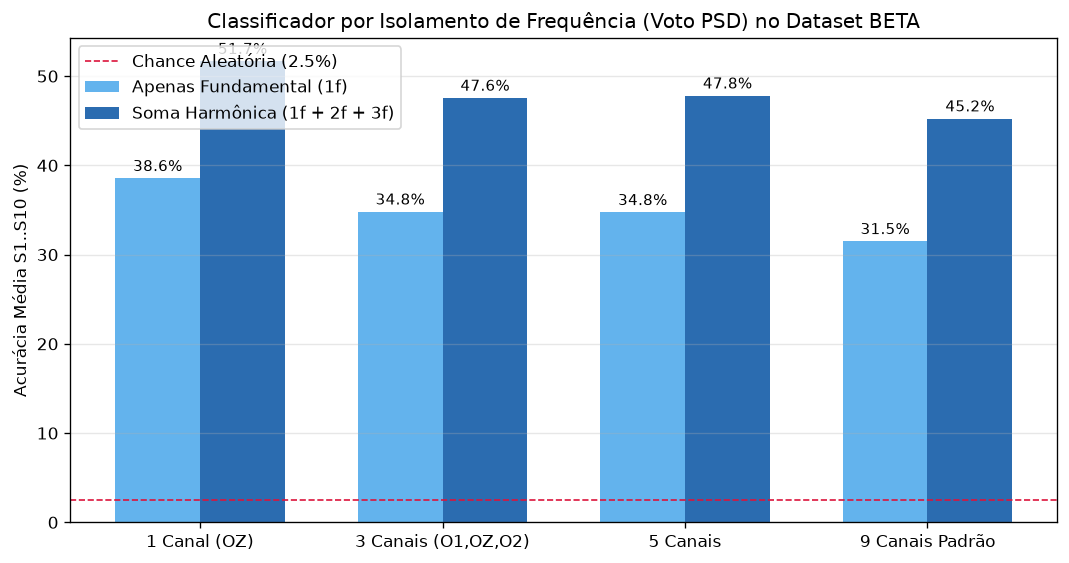

In [3]:
presets = ["oz", "3ch", "5ch", "9ch"]
voting_results = {p: {"1f": [], "3f": []} for p in presets}

for sub_id in range(1, 11):
    for p in presets:
        X_sub, y_f, _, _, meta = load_beta_subject(sub_id, channels=p, window="stim_latency")
        X_filt = butter_bandpass(butter_notch(X_sub, 50.0, fs=meta["sfreq"]), 8.0, 64.0, fs=meta["sfreq"])
        ep_sub = create_beta_epochs(X_filt, y_f, ch_names=meta["ch_names"], sfreq=meta["sfreq"])

        yp1, _ = classify_by_psd_voting(ep_sub, threshold=0.08, agg_mode="max", method="periodogram", n_harmonics=1)
        yp3, _ = classify_by_psd_voting(ep_sub, threshold=0.08, agg_mode="max", method="periodogram", n_harmonics=3)

        voting_results[p]["1f"].append(100.0 * np.mean(np.isclose(yp1, y_f)))
        voting_results[p]["3f"].append(100.0 * np.mean(np.isclose(yp3, y_f)))

print("Resumo de Acurácia Média ± Desvio Padrão (S1..S10 — 40 classes, chance = 2.50%):")
for p in presets:
    m1, s1 = np.mean(voting_results[p]["1f"]), np.std(voting_results[p]["1f"])
    m3, s3 = np.mean(voting_results[p]["3f"]), np.std(voting_results[p]["3f"])
    print(f"  Canais {p:>3s} | Fundamental (1f): {m1:5.2f}% ± {s1:5.2f}% | Com Harmônicos (1f+2f+3f): {m3:5.2f}% ± {s3:5.2f}%")

fig, ax = plt.subplots(figsize=(9, 4.8))
x_pos = np.arange(len(presets))
width = 0.35
means_1f = [np.mean(voting_results[p]["1f"]) for p in presets]
means_3f = [np.mean(voting_results[p]["3f"]) for p in presets]

b1 = ax.bar(x_pos - width/2, means_1f, width, label="Apenas Fundamental (1f)", color="#63b3ed")
b2 = ax.bar(x_pos + width/2, means_3f, width, label="Soma Harmônica (1f + 2f + 3f)", color="#2b6cb0")
ax.axhline(2.5, color="crimson", linestyle="--", linewidth=1, label="Chance Aleatória (2.5%)")
ax.set_xticks(x_pos)
ax.set_xticklabels(["1 Canal (OZ)", "3 Canais (O1,OZ,O2)", "5 Canais", "9 Canais Padrão"])
ax.set_ylabel("Acurácia Média S1..S10 (%)")
ax.set_title("Classificador por Isolamento de Frequência (Voto PSD) no Dataset BETA")
ax.legend()
ax.grid(axis="y", alpha=0.3)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.8, f"{h:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()